# Week 7 — Analisis Data dan Machine Learning

Notebook ini berisi pengerjaan soal praktikum dari file UTS yang diberikan. Penjelasannya dibuat singkat supaya gampang diikuti, sementara kode dan grafiknya bisa langsung dicoba di Jupyter Notebook.

**Sebelum menjalankan:** letakkan file CSV di folder yang sama dengan notebook. File `users_data_cleaned.pickle` untuk Soal 1 belum ikut terlampir, jadi bagian itu sudah disiapkan tetapi baru akan menampilkan hasil kalau file tersebut sudah tersedia.

In [1]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.cluster import KMeans

sns.set_theme()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Library siap digunakan.")

Library siap digunakan.


---

# Soal 1 — Eksplorasi Data `users_data_cleaned.pickle`

Di bagian ini kita mengecek isi dataset dulu, baru lanjut ke ringkasan statistik dan visualisasi. Karena file pickle belum ada di lampiran, kode akan mengecek keberadaan file sebelum menjalankan analisis.

## 1.1 Load dan preview data

In [2]:
file_pickle = Path("users_data_cleaned.pickle")

if file_pickle.exists():
    df_users = pd.read_pickle(file_pickle)
    print("Ukuran awal dataset:", df_users.shape)
    display(df_users.head())
else:
    df_users = None
    print("File users_data_cleaned.pickle belum ditemukan.")
    print("Letakkan file tersebut di folder yang sama dengan notebook, lalu jalankan ulang bagian Soal 1.")

File users_data_cleaned.pickle belum ditemukan.
Letakkan file tersebut di folder yang sama dengan notebook, lalu jalankan ulang bagian Soal 1.


## 1.2 Cek ukuran dataset

In [3]:
if df_users is not None:
    print("Jumlah baris dan kolom:", df_users.shape)
    print(f"Baris: {df_users.shape[0]} | Kolom: {df_users.shape[1]}")
else:
    print("Belum bisa dicek karena file dataset belum tersedia.")

Belum bisa dicek karena file dataset belum tersedia.


## 1.3 Cek tipe data setiap kolom

In [4]:
if df_users is not None:
    display(df_users.dtypes.to_frame(name="Tipe Data"))
else:
    print("Belum bisa dicek karena file dataset belum tersedia.")

Belum bisa dicek karena file dataset belum tersedia.


## 1.4 Cek korelasi

In [5]:
if df_users is not None:
    data_numerik = df_users.select_dtypes(include="number")
    korelasi = data_numerik.corr()
    display(korelasi)
else:
    print("Belum bisa dihitung karena file dataset belum tersedia.")

Belum bisa dihitung karena file dataset belum tersedia.


## 1.5 Statistik ringkas untuk kolom numerik

In [6]:
if df_users is not None:
    display(df_users.describe(include=[np.number]))
else:
    print("Statistik belum bisa dibuat karena file dataset belum tersedia.")

Statistik belum bisa dibuat karena file dataset belum tersedia.


## 1.6 Histogram semua kolom numerik

In [7]:
if df_users is not None:
    kolom_numerik = df_users.select_dtypes(include="number").columns

    if len(kolom_numerik) > 0:
        df_users[kolom_numerik].hist(figsize=(14, 10), bins=20, edgecolor="black")
        plt.suptitle("Histogram Kolom Numerik", y=1.02)
        plt.tight_layout()
        plt.show()
    else:
        print("Tidak ada kolom numerik yang bisa dibuat histogram.")
else:
    print("Histogram belum bisa dibuat karena file dataset belum tersedia.")

Histogram belum bisa dibuat karena file dataset belum tersedia.


## 1.7 Box plot untuk `age` dan `number_transactions`

In [8]:
if df_users is not None:
    kolom_transaksi = next(
        (kolom for kolom in ["number_transactions", "number_transaction"]
         if kolom in df_users.columns),
        None
    )
    kolom_box = [kolom for kolom in ["age", kolom_transaksi] if kolom and kolom in df_users.columns]

    if len(kolom_box) > 0:
        data_box = df_users[kolom_box].melt(var_name="Variabel", value_name="Nilai")
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=data_box, x="Variabel", y="Nilai")
        plt.title("Box Plot Usia dan Jumlah Transaksi")
        plt.tight_layout()
        plt.show()
    else:
        print("Kolom age atau number_transactions tidak ditemukan.")
else:
    print("Box plot belum bisa dibuat karena file dataset belum tersedia.")

Box plot belum bisa dibuat karena file dataset belum tersedia.


## 1.8 Line plot `date_joined` terhadap `total_amount_usd`

In [9]:
if df_users is not None:
    kolom_wajib = {"date_joined", "total_amount_usd"}

    if kolom_wajib.issubset(df_users.columns):
        data_garis = df_users[["date_joined", "total_amount_usd"]].copy()
        data_garis["date_joined"] = pd.to_datetime(data_garis["date_joined"], errors="coerce")
        data_garis = data_garis.dropna().sort_values("date_joined")

        if not data_garis.empty:
            plt.figure(figsize=(12, 5))
            sns.lineplot(data=data_garis, x="date_joined", y="total_amount_usd")
            plt.title("Tanggal Bergabung dan Total Amount (USD)")
            plt.xlabel("Date Joined")
            plt.ylabel("Total Amount (USD)")
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()
        else:
            print("Tidak ada baris valid untuk dibuat line plot.")
    else:
        print("Kolom date_joined atau total_amount_usd tidak ditemukan.")
else:
    print("Line plot belum bisa dibuat karena file dataset belum tersedia.")

Line plot belum bisa dibuat karena file dataset belum tersedia.


## 1.9 Scatter plot `total_amount_usd` terhadap jumlah transaksi

In [10]:
if df_users is not None:
    kolom_transaksi = next(
        (kolom for kolom in ["number_transactions", "number_transaction"]
         if kolom in df_users.columns),
        None
    )

    if kolom_transaksi and "total_amount_usd" in df_users.columns:
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=df_users, x=kolom_transaksi, y="total_amount_usd")
        plt.title("Jumlah Transaksi dan Total Amount (USD)")
        plt.tight_layout()
        plt.show()
    else:
        print("Kolom transaksi atau total_amount_usd tidak ditemukan.")
else:
    print("Scatter plot belum bisa dibuat karena file dataset belum tersedia.")

Scatter plot belum bisa dibuat karena file dataset belum tersedia.


## 1.10 Horizontal bar chart untuk `job`

In [11]:
if df_users is not None:
    if "job" in df_users.columns:
        hitung_job = df_users["job"].fillna("Missing").value_counts().sort_values()
        plt.figure(figsize=(9, max(4, len(hitung_job) * 0.3)))
        hitung_job.plot(kind="barh")
        plt.title("Jumlah Data berdasarkan Job")
        plt.xlabel("Jumlah")
        plt.ylabel("Job")
        plt.tight_layout()
        plt.show()
    else:
        print("Kolom job tidak ditemukan.")
else:
    print("Grafik job belum bisa dibuat karena file dataset belum tersedia.")

Grafik job belum bisa dibuat karena file dataset belum tersedia.


## 1.11 Horizontal bar chart untuk `marital`

In [12]:
if df_users is not None:
    if "marital" in df_users.columns:
        hitung_marital = df_users["marital"].fillna("Missing").value_counts().sort_values()
        plt.figure(figsize=(8, 4))
        hitung_marital.plot(kind="barh")
        plt.title("Jumlah Data berdasarkan Status Marital")
        plt.xlabel("Jumlah")
        plt.ylabel("Marital")
        plt.tight_layout()
        plt.show()
    else:
        print("Kolom marital tidak ditemukan.")
else:
    print("Grafik marital belum bisa dibuat karena file dataset belum tersedia.")

Grafik marital belum bisa dibuat karena file dataset belum tersedia.


## 1.12 Heatmap korelasi

In [13]:
if df_users is not None:
    data_numerik = df_users.select_dtypes(include="number")
    if data_numerik.shape[1] >= 2:
        plt.figure(figsize=(10, 7))
        sns.heatmap(data_numerik.corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
        plt.title("Heatmap Korelasi Kolom Numerik")
        plt.tight_layout()
        plt.show()
    else:
        print("Kolom numerik kurang dari dua, jadi heatmap korelasi belum bisa dibuat.")
else:
    print("Heatmap belum bisa dibuat karena file dataset belum tersedia.")

Heatmap belum bisa dibuat karena file dataset belum tersedia.


## 1.13 Identifikasi missing values

In [14]:
if df_users is not None:
    missing = df_users.isna().sum().sort_values(ascending=False)
    ringkasan_missing = pd.DataFrame({
        "Jumlah Missing": missing,
        "Persentase Missing (%)": (missing / len(df_users) * 100).round(2)
    })
    display(ringkasan_missing)
else:
    print("Missing values belum bisa dicek karena file dataset belum tersedia.")

Missing values belum bisa dicek karena file dataset belum tersedia.


---

# Soal 2 — Prediksi Penjualan dengan Linear Regression

Dataset ini punya dua kolom utama, yaitu `BiayaPromo` dan `NilaiPenjualan`. Model akan belajar dari 80% data, lalu diuji menggunakan 20% sisanya. Pemisah pada file CSV adalah titik koma (`;`), jadi pembacaannya disesuaikan.

## 2.1 Membaca dan melihat data

In [15]:
sales = pd.read_csv("Sales_Data.csv", sep=";")
sales.columns = sales.columns.str.strip()

# Pastikan kolom terbaca sebagai angka
for kolom in ["BiayaPromo", "NilaiPenjualan"]:
    sales[kolom] = pd.to_numeric(sales[kolom], errors="coerce")

sales = sales.dropna(subset=["BiayaPromo", "NilaiPenjualan"]).copy()

print("Ukuran dataset:", sales.shape)
display(sales.head())
print("\nNama variabel:", sales.columns.tolist())
display(sales.describe())

Ukuran dataset: (20, 2)


,BiayaPromo,NilaiPenjualan
0,1500,90500
1,1800,89500
2,1900,105000
3,2050,102000
4,2050,90500



Nama variabel: ['BiayaPromo', 'NilaiPenjualan']


,BiayaPromo,NilaiPenjualan
count,20.000000,20.00000
mean,3022.500000,151175.00000
std,931.393269,44152.33051
min,1500.000000,89500.00000
25%,2087.500000,104875.00000
50%,3200.000000,152500.00000
75%,3787.500000,188875.00000
max,4500.000000,224500.00000


## 2.2 Membagi data train 80% dan test 20%

In [16]:
X = sales[["BiayaPromo"]]
y = sales["NilaiPenjualan"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Jumlah data train:", len(X_train))
print("Jumlah data test :", len(X_test))

print("\nContoh data train:")
display(X_train.assign(NilaiPenjualan=y_train).head())

print("Contoh data test:")
display(X_test.assign(NilaiPenjualan=y_test).head())

Jumlah data train: 16
Jumlah data test : 4

Contoh data train:


,BiayaPromo,NilaiPenjualan
8,3050,152000
5,2100,104500
11,3500,174500
3,2050,102000
18,4100,204500


Contoh data test:


,BiayaPromo,NilaiPenjualan
0,1500,90500
17,4000,170500
15,3900,194500
1,1800,89500


## 2.3 Membuat dan melatih model Linear Regression

In [17]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

print("Model berhasil dilatih.")
print("Intercept:", model_lr.intercept_)
print("Slope:", model_lr.coef_[0])

Model berhasil dilatih.
Intercept: 7328.681859251141
Slope: 47.94398152795902


## 2.4 Prediksi pada data test

In [18]:
y_pred = model_lr.predict(X_test)

hasil_prediksi = pd.DataFrame({
    "BiayaPromo": X_test["BiayaPromo"].values,
    "Penjualan_Aktual": y_test.values,
    "Penjualan_Prediksi": y_pred.round(2)
})
hasil_prediksi["Selisih"] = (
    hasil_prediksi["Penjualan_Aktual"] - hasil_prediksi["Penjualan_Prediksi"]
).round(2)

display(hasil_prediksi.sort_values("BiayaPromo").reset_index(drop=True))

,BiayaPromo,Penjualan_Aktual,Penjualan_Prediksi,Selisih
0,1500,90500,79244.65,11255.35
1,1800,89500,93627.85,-4127.85
2,3900,194500,194310.21,189.79
3,4000,170500,199104.61,-28604.61


## 2.5 Menghitung R-Square

In [19]:
r_square = model_lr.score(X_test, y_test)

print(f"Intercept : {model_lr.intercept_:.2f}")
print(f"Slope     : {model_lr.coef_[0]:.2f}")
print(f"R-Square  : {r_square:.4f}")

print("\nCatatan:")
print("- Intercept adalah perkiraan penjualan saat biaya promosi bernilai 0.")
print("- Slope menunjukkan perubahan prediksi penjualan untuk setiap kenaikan 1 satuan biaya promosi.")
print("- R-Square dihitung pada data test; nilainya menunjukkan seberapa baik model menjelaskan variasi penjualan pada data tersebut.")

Intercept : 7328.68
Slope     : 47.94
R-Square  : 0.8912

Catatan:
- Intercept adalah perkiraan penjualan saat biaya promosi bernilai 0.
- Slope menunjukkan perubahan prediksi penjualan untuk setiap kenaikan 1 satuan biaya promosi.
- R-Square dihitung pada data test; nilainya menunjukkan seberapa baik model menjelaskan variasi penjualan pada data tersebut.


## 2.6 Grafik data penjualan dan garis prediksi

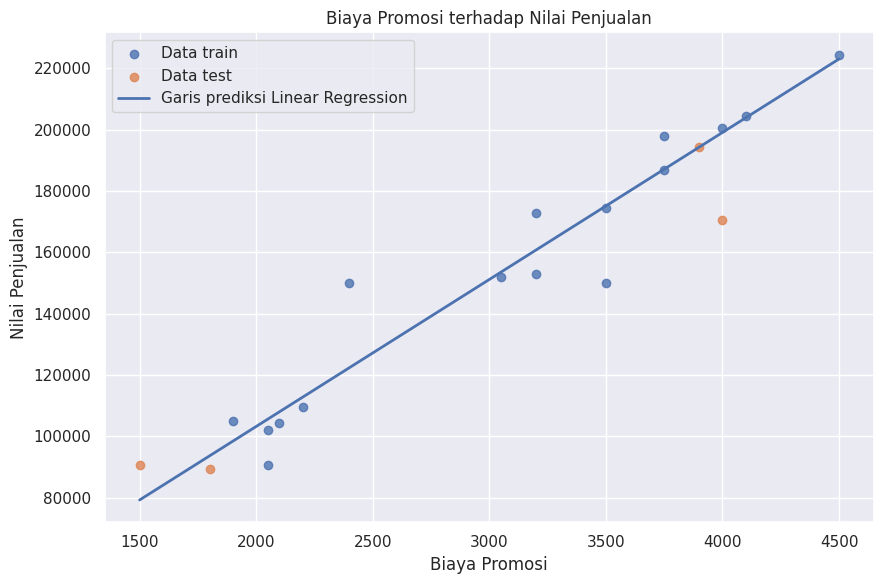

In [20]:
plt.figure(figsize=(9, 6))
plt.scatter(X_train["BiayaPromo"], y_train, label="Data train", alpha=0.8)
plt.scatter(X_test["BiayaPromo"], y_test, label="Data test", alpha=0.8)

x_garis = pd.DataFrame({"BiayaPromo": np.linspace(sales["BiayaPromo"].min(), sales["BiayaPromo"].max(), 100)})
y_garis = model_lr.predict(x_garis)

plt.plot(x_garis["BiayaPromo"], y_garis, label="Garis prediksi Linear Regression", linewidth=2)
plt.title("Biaya Promosi terhadap Nilai Penjualan")
plt.xlabel("Biaya Promosi")
plt.ylabel("Nilai Penjualan")
plt.legend()
plt.tight_layout()
plt.show()

---

# Soal 3 — NIM Ganjil: Klasifikasi Diabetes dengan K-NN

Kolom `class` dipakai sebagai label. Nilai 0 dan 1 mengikuti isi dataset. Sebelum memakai K-NN, fitur distandardisasi dulu supaya kolom dengan rentang angka besar tidak mendominasi perhitungan jarak Euclidean.

## 3.1 Membaca dataset dan menampilkan 8 baris teratas

In [21]:
pima = pd.read_csv("pima-indians-diabetes.data.csv")

print("Ukuran dataset:", pima.shape)
display(pima.head(8))

Ukuran dataset: (768, 9)


,preg,glukosa,pres,skin,insulin,BMI,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0


## 3.2 Memisahkan fitur dan label, lalu melihat 9 baris teratas

In [22]:
X_pima = pima.drop(columns=["class"])
y_pima = pima["class"]

print("Fitur (X):")
display(X_pima.head(9))

print("Label (y):")
display(y_pima.head(9).to_frame())

Fitur (X):


,preg,glukosa,pres,skin,insulin,BMI,pedi,age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
5,5,116,74,0,0,25.6,0.201,30
6,3,78,50,32,88,31.0,0.248,26
7,10,115,0,0,0,35.3,0.134,29
8,2,197,70,45,543,30.5,0.158,53


Label (y):


,class
0,1
1,0
2,1
3,0
4,1
5,0
6,1
7,0
8,1


## 3.3 Membagi data train 85% dan test 15%

In [23]:
X_train_pima, X_test_pima, y_train_pima, y_test_pima = train_test_split(
    X_pima,
    y_pima,
    test_size=0.15,
    random_state=42,
    stratify=y_pima
)

print("Ukuran X_train:", X_train_pima.shape)
print("Ukuran X_test :", X_test_pima.shape)
print("Ukuran y_train:", y_train_pima.shape)
print("Ukuran y_test :", y_test_pima.shape)

print("\nContoh data train:")
display(X_train_pima.head())

print("Contoh data test:")
display(X_test_pima.head())

Ukuran X_train: (652, 8)
Ukuran X_test : (116, 8)
Ukuran y_train: (652,)
Ukuran y_test : (116,)

Contoh data train:


,preg,glukosa,pres,skin,insulin,BMI,pedi,age
110,3,171,72,33,135,33.3,0.199,24
594,6,123,72,45,230,33.6,0.733,34
732,2,174,88,37,120,44.5,0.646,24
323,13,152,90,33,29,26.8,0.731,43
561,0,198,66,32,274,41.3,0.502,28


Contoh data test:


,preg,glukosa,pres,skin,insulin,BMI,pedi,age
440,0,189,104,25,0,34.3,0.435,41
264,4,123,62,0,0,32.0,0.226,35
392,1,131,64,14,415,23.7,0.389,21
116,5,124,74,0,0,34.0,0.220,38
304,3,150,76,0,0,21.0,0.207,37


## 3.4 Melatih K-NN dengan 5 tetangga dan jarak Euclidean

In [24]:
scaler_pima = StandardScaler()
X_train_scaled = scaler_pima.fit_transform(X_train_pima)
X_test_scaled = scaler_pima.transform(X_test_pima)

knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn.fit(X_train_scaled, y_train_pima)

prediksi_knn = knn.predict(X_test_scaled)
akurasi_knn = accuracy_score(y_test_pima, prediksi_knn)

print("Akurasi K-NN (k=5):", round(akurasi_knn, 4))
print("\nContoh hasil prediksi:")
display(pd.DataFrame({
    "Label Aktual": y_test_pima.to_numpy(),
    "Label Prediksi": prediksi_knn
}).head(10))

Akurasi K-NN (k=5): 0.7155

Contoh hasil prediksi:


,Label Aktual,Label Prediksi
0,1,0
1,1,0
2,0,0
3,1,1
4,0,0
5,0,0
6,0,1
7,0,0
8,1,1
9,0,0


## 3.5 Grafik hubungan nilai k dengan akurasi

,k,Akurasi Train,Akurasi Test
0,1,1.0000,0.6897
1,2,0.8420,0.7241
2,3,0.8574,0.7155
3,4,0.8098,0.7241
4,5,0.8113,0.7155
5,6,0.8037,0.7500
6,7,0.8006,0.7672
7,8,0.8021,0.7500
8,9,0.7960,0.7759
9,10,0.7868,0.7586


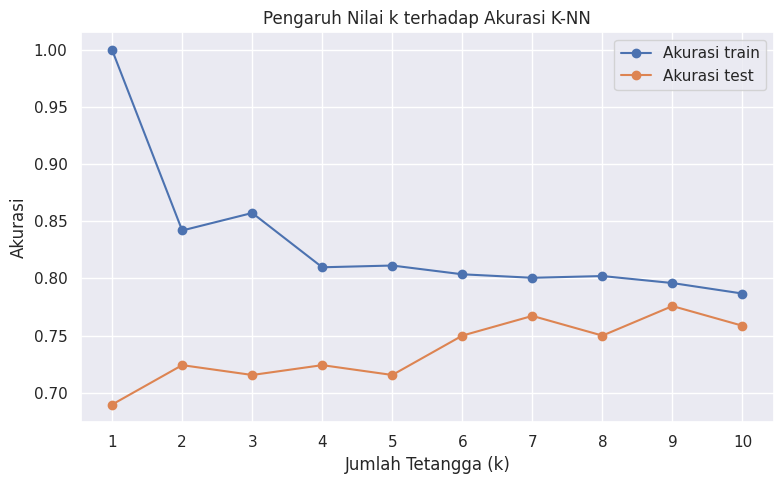

Nilai k dengan akurasi test tertinggi pada percobaan ini: 9
Akurasi test: 0.7759


In [25]:
daftar_k = range(1, 11)
akurasi_train = []
akurasi_test = []

for k in daftar_k:
    model_k = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    model_k.fit(X_train_scaled, y_train_pima)

    pred_train = model_k.predict(X_train_scaled)
    pred_test = model_k.predict(X_test_scaled)

    akurasi_train.append(accuracy_score(y_train_pima, pred_train))
    akurasi_test.append(accuracy_score(y_test_pima, pred_test))

hasil_k = pd.DataFrame({
    "k": list(daftar_k),
    "Akurasi Train": akurasi_train,
    "Akurasi Test": akurasi_test
})
display(hasil_k.round(4))

plt.figure(figsize=(8, 5))
plt.plot(list(daftar_k), akurasi_train, marker="o", label="Akurasi train")
plt.plot(list(daftar_k), akurasi_test, marker="o", label="Akurasi test")
plt.xticks(list(daftar_k))
plt.xlabel("Jumlah Tetangga (k)")
plt.ylabel("Akurasi")
plt.title("Pengaruh Nilai k terhadap Akurasi K-NN")
plt.legend()
plt.tight_layout()
plt.show()

k_terbaik = hasil_k.loc[hasil_k["Akurasi Test"].idxmax()]
print(f"Nilai k dengan akurasi test tertinggi pada percobaan ini: {int(k_terbaik['k'])}")
print(f"Akurasi test: {k_terbaik['Akurasi Test']:.4f}")

---

# Soal 3 — NIM Genap: Clustering Konsumen dengan K-Means

Bagian ini mengelompokkan konsumen berdasarkan `Gaji` dan `Pengeluaran`. Kolom `No` hanya berfungsi sebagai nomor urut, jadi tidak dipakai saat membentuk cluster.

## 3.6 Membaca data dan menampilkan 7 baris teratas

In [26]:
konsumen = pd.read_csv("konsumen.csv", sep=";")
konsumen.columns = konsumen.columns.str.strip()

for kolom in ["No", "Gaji", "Pengeluaran"]:
    if kolom in konsumen.columns:
        konsumen[kolom] = pd.to_numeric(konsumen[kolom], errors="coerce")

konsumen = konsumen.dropna(subset=["Gaji", "Pengeluaran"]).copy()
display(konsumen.head(7))

,No,Gaji,Pengeluaran
0,1,2500,1750
1,2,3800,4200
2,3,3900,3800
3,4,4350,5500
4,5,4400,3200
5,6,5500,5450
6,7,5600,5950


## 3.7 Menghapus kolom `No` dan melihat 9 baris teratas

In [27]:
konsumen_model = konsumen.drop(columns=["No"], errors="ignore")
display(konsumen_model.head(9))

,Gaji,Pengeluaran
0,2500,1750
1,3800,4200
2,3900,3800
3,4350,5500
4,4400,3200
5,5500,5450
6,5600,5950
7,5750,4100
8,6850,6050


## 3.8 Grafik hubungan gaji dan pengeluaran

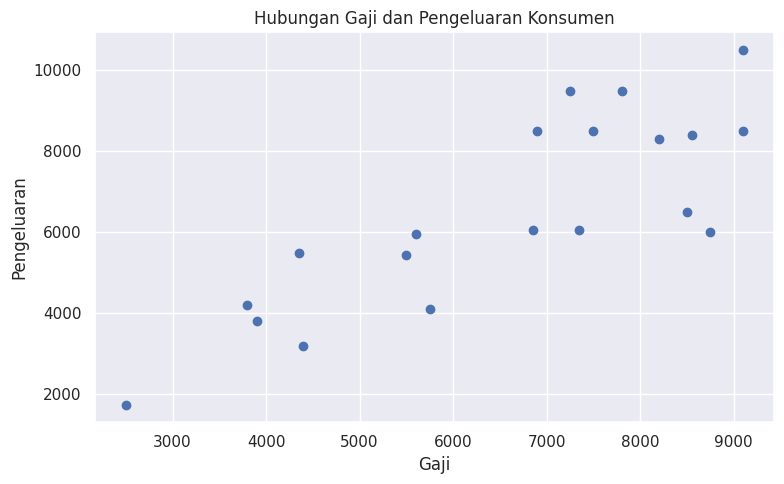

In [28]:
plt.figure(figsize=(8, 5))
plt.scatter(konsumen_model["Gaji"], konsumen_model["Pengeluaran"])
plt.title("Hubungan Gaji dan Pengeluaran Konsumen")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.tight_layout()
plt.show()

## 3.9 Membentuk 2 cluster dengan K-Means dan melihat pusat cluster

In [29]:
fitur_kmeans = ["Gaji", "Pengeluaran"]
X_konsumen = konsumen_model[fitur_kmeans]

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
konsumen_model["Cluster"] = kmeans.fit_predict(X_konsumen)

pusat_cluster = pd.DataFrame(kmeans.cluster_centers_, columns=fitur_kmeans)
pusat_cluster.index = [f"Cluster {i}" for i in pusat_cluster.index]

print("Pusat cluster:")
display(pusat_cluster.round(2))

print("Data konsumen beserta cluster:")
display(konsumen_model.head(10))

Pusat cluster:


,Gaji,Pengeluaran
Cluster 0,4475.0,4243.75
Cluster 1,7987.5,8025.00


Data konsumen beserta cluster:


,Gaji,Pengeluaran,Cluster
0,2500,1750,0
1,3800,4200,0
2,3900,3800,0
3,4350,5500,0
4,4400,3200,0
5,5500,5450,0
6,5600,5950,0
7,5750,4100,0
8,6850,6050,1
9,6900,8500,1


## 3.10 Grafik konsumen dengan dua warna berbeda

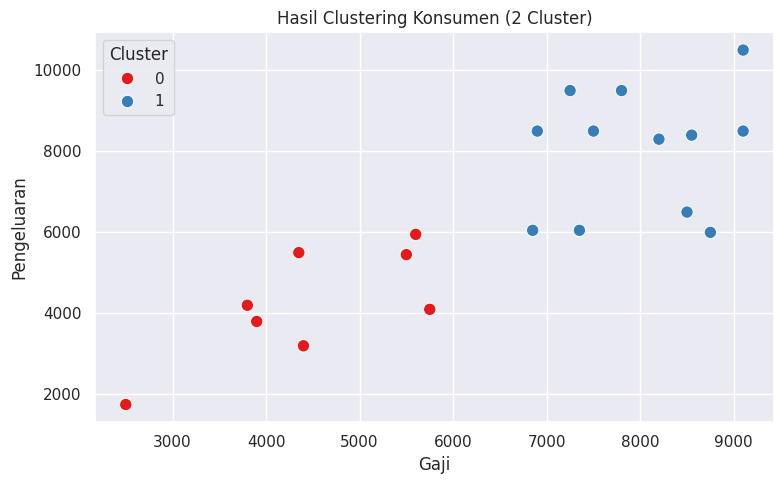

In [30]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=konsumen_model,
    x="Gaji",
    y="Pengeluaran",
    hue="Cluster",
    palette="Set1",
    s=80
)
plt.title("Hasil Clustering Konsumen (2 Cluster)")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 3.11 Grafik cluster beserta pusat cluster

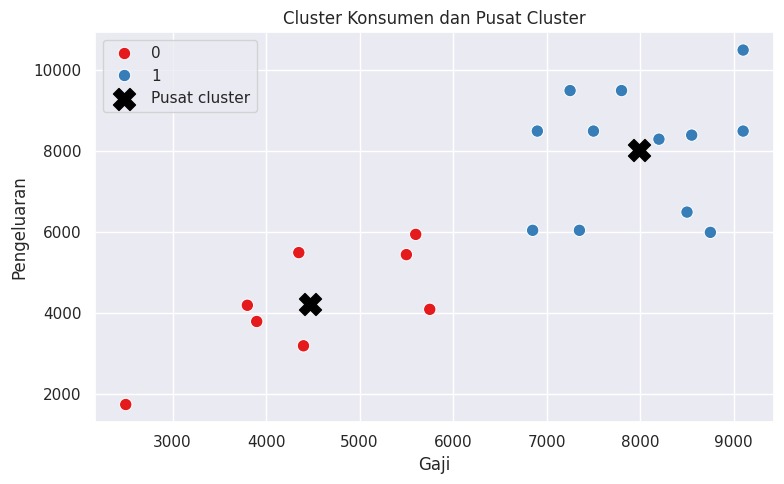

In [31]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=konsumen_model,
    x="Gaji",
    y="Pengeluaran",
    hue="Cluster",
    palette="Set1",
    s=80
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Pusat cluster"
)

plt.title("Cluster Konsumen dan Pusat Cluster")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.legend()
plt.tight_layout()
plt.show()

## Kesimpulan singkat

- **Linear Regression** digunakan untuk melihat hubungan biaya promosi dengan nilai penjualan. Nilai intercept, slope, dan R-Square ditampilkan dari model yang dilatih.
- **K-NN** mengklasifikasikan data berdasarkan tetangga terdekat. Grafik membandingkan akurasi train dan test untuk nilai k dari 1 sampai 10.
- **K-Means** membagi konsumen menjadi dua kelompok berdasarkan gaji dan pengeluaran. Pusat cluster menunjukkan titik tengah dari masing-masing kelompok.

Hasil angka dan grafik mengikuti dataset yang dibaca saat notebook dijalankan.